Données chargées avec succès ! Forme de X : (450, 2), Nombre de classes : 3
Époque 100/1000 - Perte (Loss): 0.5350 - Précision (Accuracy): 69.56%
Époque 200/1000 - Perte (Loss): 0.4729 - Précision (Accuracy): 76.44%
Époque 300/1000 - Perte (Loss): 0.4174 - Précision (Accuracy): 81.33%
Époque 400/1000 - Perte (Loss): 0.3672 - Précision (Accuracy): 84.89%
Époque 500/1000 - Perte (Loss): 0.3222 - Précision (Accuracy): 89.33%
Époque 600/1000 - Perte (Loss): 0.2826 - Précision (Accuracy): 93.11%
Époque 700/1000 - Perte (Loss): 0.2482 - Précision (Accuracy): 96.00%
Époque 800/1000 - Perte (Loss): 0.2188 - Précision (Accuracy): 97.78%
Époque 900/1000 - Perte (Loss): 0.1937 - Précision (Accuracy): 98.44%
Époque 1000/1000 - Perte (Loss): 0.1724 - Précision (Accuracy): 98.67%


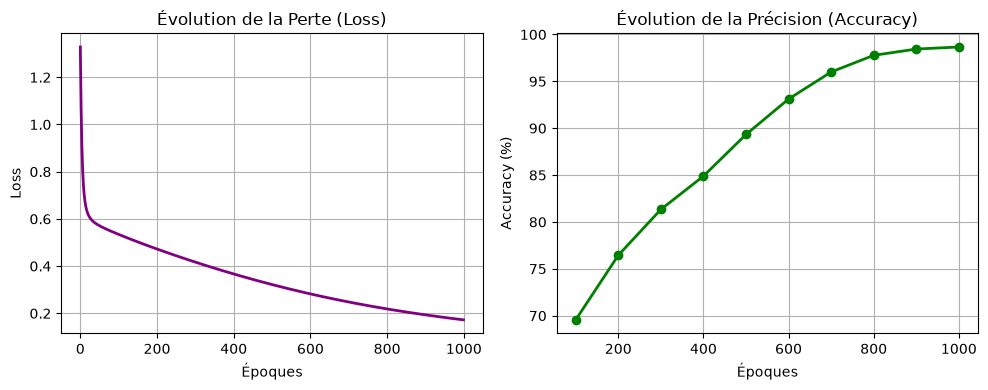

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. FONCTIONS D'ACTIVATION ET LEURS DÉRIVÉES
# ==========================================
def tanh(x):
    return np.tanh(x)

def tanh_derivative(output):
    return 1.0 - output ** 2

def softmax(x):
    # Version stable numériquement pour éviter l'overflow
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

# ==========================================
# 2. CLASSE DU RÉSEAU DE NEURONES (3 COUCHES)
# ==========================================
class NeuralNetwork:
    def __init__(self, input_dim, hidden_dim, output_dim, seed=42):
        np.random.seed(seed)
        # Initialisation de He / Xavier pour de meilleures performances
        self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2.0 / hidden_dim)
        self.b2 = np.zeros((1, output_dim))
        
    def forward(self, X):
        # Couche cachée (Tanh)
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = tanh(self.Z1)
        # Couche de sortie (Softmax)
        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = softmax(self.Z2)
        return self.A2
        
    def backward(self, X, y_one_hot, lr=0.01):
        m = X.shape[0]
        
        # Gradient de la couche de sortie (Softmax + Cross-Entropy)
        error_output = self.A2 - y_one_hot  # dZ2
        dW2 = (self.A1.T @ error_output) / m
        db2 = np.sum(error_output, axis=0, keepdims=True) / m
        
        # Gradient de la couche cachée (Tanh)
        error_hidden = (error_output @ self.W2.T) * tanh_derivative(self.A1)  # dZ1
        dW1 = (X.T @ error_hidden) / m
        db1 = np.sum(error_hidden, axis=0, keepdims=True) / m
        
        # Mise à jour des poids par Descente de Gradient Simple
        self.W1 -= lr * dW1
        self.b1 -= lr * db1
        self.W2 -= lr * dW2
        self.b2 -= lr * db2

# ==========================================
# 3. CHARGEMENT ET PRÉTRAITEMENT DES DONNÉES
# ==========================================
def load_classification_data(filepath):
    df = pd.read_csv(filepath)
    
    # Détection automatique de la colonne cible (y ou label)
    if 'y' in df.columns:
        y = df['y'].values
        X = df.drop(columns=['y', 'split'], errors='ignore').values
    elif 'label' in df.columns:
        y = df['label'].values
        X = df.drop(columns=['label', 'split'], errors='ignore').values
    else:
        X = df.iloc[:, :-1].values
        y = df.iloc[:, -1].values
        
    return X, y

def to_one_hot(y, num_classes):
    m = len(y)
    one_hot = np.zeros((m, num_classes))
    one_hot[np.arange(m), y.astype(int)] = 1
    return one_hot

# Chargement du dataset (ex: classification_spiral3.csv)
X_clf, y_clf = load_classification_data("data/classification_spiral3.csv")
num_classes = len(np.unique(y_clf))
y_clf_onehot = to_one_hot(y_clf, num_classes)

# Standardisation des caractéristiques
X_clf = (X_clf - np.mean(X_clf, axis=0)) / (np.std(X_clf, axis=0) + 1e-8)

print(f"Données chargées avec succès ! Forme de X : {X_clf.shape}, Nombre de classes : {num_classes}")

# ==========================================
# 4. ENTRAÎNEMENT ET ÉVALUATION DU MODÈLE
# ==========================================
input_dim = X_clf.shape[1]
hidden_dim = 32
output_dim = num_classes

nn = NeuralNetwork(input_dim=input_dim, hidden_dim=hidden_dim, output_dim=output_dim, seed=42)

epochs = 1000
lr = 0.05
loss_history = []
acc_history = []

for epoch in range(epochs):
    # Forward pass
    output = nn.forward(X_clf)
    
    # Calcul de la perte (Cross-Entropy Loss)
    m = X_clf.shape[0]
    loss = -np.sum(y_clf_onehot * np.log(output + 1e-15)) / m
    loss_history.append(loss)
    
    # Backward pass & mise à jour
    nn.backward(X_clf, y_clf_onehot, lr=lr)
    
    # Calcul de la précision (Accuracy) tous les 100 epochs
    if (epoch + 1) % 100 == 0:
        predictions = np.argmax(output, axis=1)
        accuracy = np.mean(predictions == y_clf) * 100
        acc_history.append(accuracy)
        print(f"Époque {epoch+1}/{epochs} - Perte (Loss): {loss:.4f} - Précision (Accuracy): {accuracy:.2f}%")

# ==========================================
# 5. VISUALISATION DES RÉSULTATS
# ==========================================
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(loss_history, color='purple', lw=2)
plt.title("Évolution de la Perte (Loss)")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(100, epochs + 1, 100), acc_history, color='green', marker='o', lw=2)
plt.title("Évolution de la Précision (Accuracy)")
plt.xlabel("Époques")
plt.ylabel("Accuracy (%)")
plt.grid(True)

plt.tight_layout()
plt.show()